# Configuración básica de una red neuronal convolucional (PyTorch)

Una vez hemos estudiado los conceptos básicos de las redes convolucionales, como las capas convolucionales y de pooling, es hora de construir nuestra propia red. Como ejemplo usaremos la base de datos Fashion MNIST.

En este notebook usaremos **PyTorch**. A diferencia de otras librerías que ocultan el ciclo de entrenamiento dentro de una función (`fit`), en PyTorch lo escribimos nosotros mismos. Esto requiere unas pocas líneas más, pero nos permite ver exactamente qué ocurre en cada paso del aprendizaje.

## Etapa 1: Se carga la base de datos.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

Si hay una GPU disponible, la usaremos para acelerar el entrenamiento; de lo contrario, se usa la CPU. Tanto el modelo como los datos deben estar en el mismo dispositivo.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


Cargamos Fashion MNIST con `torchvision`. La transformación `ToTensor()` convierte cada imagen en un tensor y **normaliza** los valores de los píxeles del rango $[0, 255]$ al intervalo $[0, 1]$.

In [3]:
train_data = datasets.FashionMNIST(root="../../../data", train=True, download=True,
                                  transform=transforms.ToTensor())
test_data = datasets.FashionMNIST(root="../../../data", train=False, download=True,
                                 transform=transforms.ToTensor())

In [4]:
# El conjunto de entrenamiento está compuesto por 60000 imágenes de tamaño 28x28
print(train_data.data.shape)

torch.Size([60000, 28, 28])


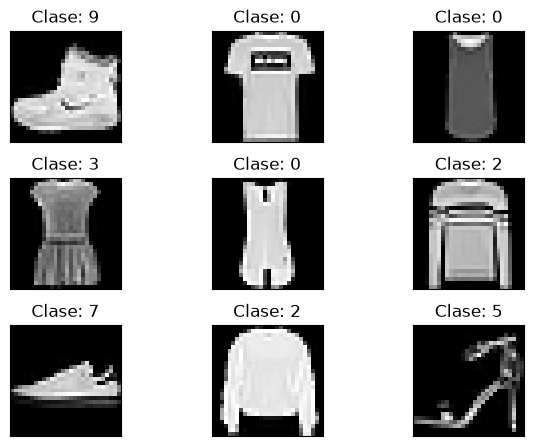

In [5]:
fig = plt.figure()
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.tight_layout()
    plt.imshow(train_data.data[i], cmap="gray", interpolation="none")
    plt.title("Clase: {}".format(train_data.targets[i].item()))
    plt.xticks([])
    plt.yticks([])
plt.show()

## Etapa 2: Se procesan las imágenes para que sean compatibles con la red convolucional.

Las imágenes ya fueron normalizadas al intervalo $[0, 1]$ por `ToTensor()`. Además, `ToTensor()` agrega una dimensión para los **canales** de la imagen. Como usamos imágenes en escala de grises, hay un solo canal. Las imágenes a color se representan usualmente con tres canales RGB (rojo, verde y azul). Para profundizar más acerca de las representaciones de las imágenes a color y en escala de grises, los invito a leer la siguiente publicación [Enlace.](https://towardsdatascience.com/exploring-the-mnist-digits-dataset-7ff62631766a)

Veamos la forma de una imagen:

In [6]:
image, label = train_data[0]
print(image.shape)  # (canales, alto, ancho)
print(image.min().item(), image.max().item())

torch.Size([1, 28, 28])
0.0 1.0


**Una diferencia importante:** PyTorch ordena las dimensiones como `(canales, alto, ancho)`, mientras que otras librerías usan `(alto, ancho, canales)`. Con un minibatch, la forma completa es `(batch, canales, alto, ancho)`.

Ahora creamos los `DataLoader`, que se encargan de entregar los datos en **minibatches** de tamaño 32. En el conjunto de entrenamiento mezclamos (`shuffle=True`) los datos en cada época.

In [7]:
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape)  # (batch, canales, alto, ancho)
print(labels.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


## Etapa 3: Definición del modelo

Ahora, es momento de definir el modelo de redes convolucionales. Usualmente, las capas de pooling se alimentan de las salidas de las capas convolucionales. Así, se suele definir como una capa oculta al conjunto de una capa convolucional más una capa de pooling.

Para este ejemplo definimos una red simple compuesta por dos capas ocultas y una capa de salida de tipo densa (`nn.Linear`) con 10 unidades.

In [8]:
model = nn.Sequential(
    # La primera capa oculta se compone de una capa convolucional con 32 filtros,
    # cada uno con tamaño kernel_size=3x3. En PyTorch debemos indicar cuántos
    # canales tiene la entrada (in_channels=1, escala de grises) y cuántos
    # produce la capa (out_channels=32, uno por filtro). Con padding=0 (sin
    # relleno) y stride=1, la salida de la convolución será de tamaño 26x26x32.
    # Nótese que no definimos la cantidad de imágenes, pues esta dependerá del
    # tamaño del minibatch que usemos.
    nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=0),
    # La no linealidad ReLU es una capa aparte en PyTorch.
    nn.ReLU(),
    # Luego, el resultado pasa a través de una capa de Max Pooling que usa filtros
    # 2x2 y un paso de 2. De esta forma, la salida será de tamaño 13x13x32.
    nn.MaxPool2d(kernel_size=2, stride=2),

    # Definimos una nueva capa convolucional con 64 filtros. Ahora la entrada
    # tiene 32 canales (los que produjo la capa anterior). Una particularidad de
    # las redes convolucionales es que, mientras las imágenes se vuelven cada vez
    # más pequeñas por las operaciones de convolución y pooling, la cantidad de
    # filtros tiende a aumentar: aquí duplicamos de 32 a 64. Al final de la
    # convolución tendremos una salida de tamaño 11x11x64.
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0),
    nn.ReLU(),
    # Finalizamos esta capa oculta con un Max Pooling, que reduce la
    # representación a un tamaño de 5x5x64 (11/2 = 5.5, se redondea hacia abajo).
    nn.MaxPool2d(kernel_size=2, stride=2),

    # Las capas convolucionales funcionan como extractoras de características de
    # las imágenes. Luego, estas características se usan para cumplir con la tarea
    # de aprendizaje; en nuestro caso, clasificación en 10 clases. Para esto usamos
    # una capa de aplastamiento (Flatten), que convierte un arreglo de múltiples
    # dimensiones en uno de una sola dimensión. Como la entrada es de tamaño
    # 5x5x64, la salida tendrá 5*5*64 = 1600 unidades.
    nn.Flatten(),

    # Se aplica una capa de Dropout con el fin de prevenir el sobre-ajuste.
    nn.Dropout(0.5),

    # Finalmente se define la capa de salida: 10 neuronas, una por cada clase.
    # Observe que NO agregamos Softmax. La función de costo que usaremos
    # (CrossEntropyLoss) ya la incluye internamente, por lo que la red entrega
    # "logits" (puntajes sin normalizar).
    nn.Linear(in_features=5 * 5 * 64, out_features=10),
)
model = model.to(device)

Veamos un resumen del modelo. Podemos imprimirlo directamente y contar los parámetros entrenables:

In [9]:
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total de parámetros entrenables:", total_params)

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Dropout(p=0.5, inplace=False)
  (8): Linear(in_features=1600, out_features=10, bias=True)
)
Total de parámetros entrenables: 34826


Para verificar los tamaños que calculamos a mano, pasemos un minibatch de ejemplo capa por capa:

In [10]:
x = images.to(device)
for layer in model:
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")

Conv2d     -> (32, 32, 26, 26)
ReLU       -> (32, 32, 26, 26)
MaxPool2d  -> (32, 32, 13, 13)
Conv2d     -> (32, 64, 11, 11)
ReLU       -> (32, 64, 11, 11)
MaxPool2d  -> (32, 64, 5, 5)
Flatten    -> (32, 1600)
Dropout    -> (32, 1600)


Linear     -> (32, 10)


Los parámetros coinciden con lo esperado:

- Primera convolución: $(3 \times 3 \times 1 + 1) \times 32 = 320$
- Segunda convolución: $(3 \times 3 \times 32 + 1) \times 64 = 18496$
- Capa densa: $(1600 + 1) \times 10 = 16010$

Total: $34826$ parámetros.

# Etapa 4: Entrenamiento y evaluación del modelo

Definimos la función de costo y el optimizador:

- `CrossEntropyLoss`: entropía cruzada para clasificación multiclase (incluye la Softmax).
- `Adam`: el optimizador ADAM, que recibe los parámetros del modelo que debe actualizar.

Además, escribimos dos funciones: una para entrenar durante una época y otra para evaluar.

In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [12]:
def train_one_epoch(model, loader):
    model.train()  # activa el Dropout
    total_loss, correct = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # 1. Paso hacia adelante: calculamos las predicciones y el costo
        logits = model(images)
        loss = loss_fn(logits, labels)

        # 2. Paso hacia atrás: calculamos los gradientes
        optimizer.zero_grad()  # se borran los gradientes del minibatch anterior
        loss.backward()

        # 3. Se actualizan los parámetros
        optimizer.step()

        total_loss += loss.item() * images.shape[0]
        correct += (logits.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def evaluate(model, loader):
    model.eval()  # desactiva el Dropout
    total_loss, correct = 0.0, 0
    with torch.no_grad():  # no necesitamos gradientes al evaluar
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * images.shape[0]
            correct += (logits.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

Entrenamos el modelo con minibatches de tamaño 32 durante 10 épocas. En cada época recorremos todo el conjunto de entrenamiento y luego medimos el rendimiento en el conjunto de prueba.

In [13]:
epochs = 10
history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, test_loader)
    history["loss"].append(train_loss)
    history["accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    print(f"Época {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
          f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

Época 1/10 - loss: 0.5573 - accuracy: 0.7965 - val_loss: 0.4063 - val_accuracy: 0.8551


Época 2/10 - loss: 0.3996 - accuracy: 0.8561 - val_loss: 0.3683 - val_accuracy: 0.8627


Época 3/10 - loss: 0.3557 - accuracy: 0.8714 - val_loss: 0.3233 - val_accuracy: 0.8828


Época 4/10 - loss: 0.3352 - accuracy: 0.8782 - val_loss: 0.3091 - val_accuracy: 0.8888


Época 5/10 - loss: 0.3160 - accuracy: 0.8848 - val_loss: 0.3044 - val_accuracy: 0.8912


Época 6/10 - loss: 0.3052 - accuracy: 0.8891 - val_loss: 0.2865 - val_accuracy: 0.9003


Época 7/10 - loss: 0.2966 - accuracy: 0.8913 - val_loss: 0.2759 - val_accuracy: 0.9015


Época 8/10 - loss: 0.2885 - accuracy: 0.8943 - val_loss: 0.2883 - val_accuracy: 0.8965


Época 9/10 - loss: 0.2813 - accuracy: 0.8963 - val_loss: 0.2732 - val_accuracy: 0.8999


Época 10/10 - loss: 0.2747 - accuracy: 0.8985 - val_loss: 0.2820 - val_accuracy: 0.8954


Finalmente, se evalúa el rendimiento del modelo en el conjunto de prueba.

In [14]:
test_loss, test_acc = evaluate(model, test_loader)
print("Test accuracy:", test_acc)

Test accuracy: 0.8954


Podemos visualizar la evolución del entrenamiento:

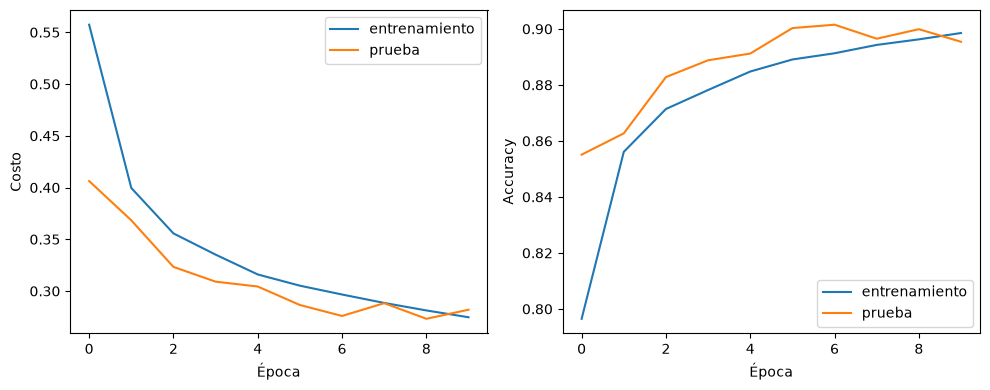

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["loss"], label="entrenamiento")
axes[0].plot(history["val_loss"], label="prueba")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Costo")
axes[0].legend()
axes[1].plot(history["accuracy"], label="entrenamiento")
axes[1].plot(history["val_accuracy"], label="prueba")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()